In [3]:
import pandas as pd
import numpy as np
import polars as pl

In [5]:
df = pl.read_csv("prices_round_0_day_-1.csv")
prices_df_0 = df.to_pandas()
prices_df_0.head()



,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,-1,0,TOMATOES,4999,5,4998,15,NaN,NaN,5013,5,5014,15,NaN,NaN,5006.0,0.0
1,-1,0,EMERALDS,9992,14,9990,29,NaN,NaN,10008,14,10010,29,NaN,NaN,10000.0,0.0
2,-1,100,EMERALDS,9992,11,9990,22,NaN,NaN,10008,11,10010,22,NaN,NaN,10000.0,0.0
3,-1,100,TOMATOES,5000,8,4998,21,NaN,NaN,5013,8,5014,21,NaN,NaN,5006.5,0.0
4,-1,200,EMERALDS,9992,15,9990,20,NaN,NaN,10008,15,10010,20,NaN,NaN,10000.0,0.0


day                      -2
timestamp               900
product            TOMATOES
bid_price_1            4994
bid_volume_1              5
bid_price_2            4993
bid_volume_2             24
bid_price_3             NaN
bid_volume_3            NaN
ask_price_1            5008
ask_volume_1              5
ask_price_2            5009
ask_volume_2             24
ask_price_3             NaN
ask_volume_3            NaN
mid_price            5001.0
profit_and_loss         0.0
Name: 18, dtype: object

In [7]:
df = pl.read_csv("prices_round_0_day_-2.csv")
prices_df_1 = df.to_pandas()
prices_df_1.head()


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
0,-2,0,EMERALDS,9992,11,9990,25,NaN,NaN,10008,11,10010,25,NaN,NaN,10000.0,0.0
1,-2,0,TOMATOES,4993,7,4992,17,NaN,NaN,5007,7,5008,17,NaN,NaN,5000.0,0.0
2,-2,100,TOMATOES,4998,5,4993,7,4992.0,16.0,5007,7,5008,16,NaN,NaN,5002.5,0.0
3,-2,100,EMERALDS,9992,15,9990,20,NaN,NaN,10008,15,10010,20,NaN,NaN,10000.0,0.0
4,-2,200,TOMATOES,4994,6,4993,20,NaN,NaN,5008,6,5009,20,NaN,NaN,5001.0,0.0


In [9]:
df = pl.read_csv("trades_round_0_day_-1.csv")
trades_df_0 = df.to_pandas()
trades_df_0.head()

,timestamp,buyer,seller,symbol,currency,price,quantity
0,3200,None,None,EMERALDS,XIRECS,9992.0,8
1,3400,None,None,TOMATOES,XIRECS,5009.0,2
2,5000,None,None,EMERALDS,XIRECS,9992.0,7
3,7000,None,None,TOMATOES,XIRECS,5010.0,4
4,9600,None,None,TOMATOES,XIRECS,4999.0,5


In [11]:
df = pl.read_csv("trades_round_0_day_-2.csv")
trades_df_1 = df.to_pandas()
trades_df_1.head()

,timestamp,buyer,seller,symbol,currency,price,quantity
0,900,None,None,TOMATOES,XIRECS,5008.0,2
1,1700,None,None,TOMATOES,XIRECS,5006.0,3
2,4000,None,None,EMERALDS,XIRECS,10008.0,7
3,4100,None,None,TOMATOES,XIRECS,5002.0,3
4,5200,None,None,EMERALDS,XIRECS,9992.0,5


In [12]:
trades_df_0

,timestamp,buyer,seller,symbol,currency,price,quantity
0,3200,None,None,EMERALDS,XIRECS,9992.0,8
1,3400,None,None,TOMATOES,XIRECS,5009.0,2
2,5000,None,None,EMERALDS,XIRECS,9992.0,7
3,7000,None,None,TOMATOES,XIRECS,5010.0,4
4,9600,None,None,TOMATOES,XIRECS,4999.0,5
...,...,...,...,...,...,...,...
626,983800,None,None,EMERALDS,XIRECS,10008.0,3
627,985100,None,None,TOMATOES,XIRECS,4946.0,2
628,985600,None,None,EMERALDS,XIRECS,10008.0,6
629,993000,None,None,TOMATOES,XIRECS,4956.0,2


In [13]:
trades_df_1

,timestamp,buyer,seller,symbol,currency,price,quantity
0,900,None,None,TOMATOES,XIRECS,5008.0,2
1,1700,None,None,TOMATOES,XIRECS,5006.0,3
2,4000,None,None,EMERALDS,XIRECS,10008.0,7
3,4100,None,None,TOMATOES,XIRECS,5002.0,3
4,5200,None,None,EMERALDS,XIRECS,9992.0,5
...,...,...,...,...,...,...,...
583,986100,None,None,TOMATOES,XIRECS,5002.0,5
584,988600,None,None,TOMATOES,XIRECS,5004.0,5
585,989300,None,None,TOMATOES,XIRECS,5017.0,2
586,991500,None,None,TOMATOES,XIRECS,5017.0,2


## Visualising the Price Gain Percentages

In [32]:
from tqdm import tqdm

def f1(x):
    if pd.isna(x):
        return 0
    else:
        return x

prices_df_0['avg_bid_prices'] = [
    (f1(w1*p1)+f1(w2*p2)+f1(w3*p3))/(f1(w1)+f1(w2)+f1(w3)) for w1,w2,w3,p1,p2,p3 in tqdm(zip(
        prices_df_0['bid_volume_1'].to_list(),
        prices_df_0['bid_volume_2'].to_list(),
        prices_df_0['bid_volume_3'].to_list(),
        prices_df_0['bid_price_1'].to_list(),
        prices_df_0['bid_price_2'].to_list(),
        prices_df_0['bid_price_3'].to_list(),
    ))
]




20000it [00:00, 660411.11it/s]


Average movement of tomatoes


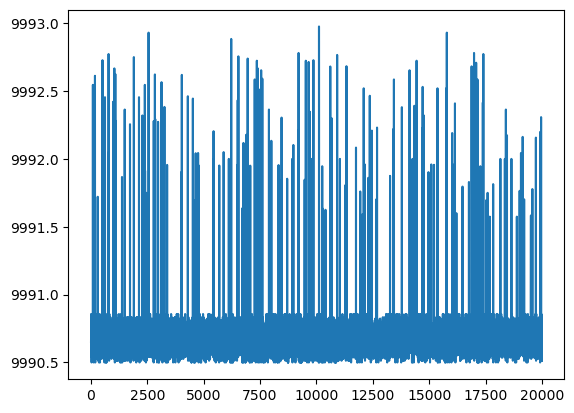

In [36]:
from matplotlib import pyplot as plt
print("Average movement of tomatoes")
#prices_df_0[prices_df_0['product']=='TOMATOES']['avg_bid_prices'].plot()
prices_df_0[prices_df_0['product']=='EMERALDS']['avg_bid_prices'].plot()
plt.show()






In [38]:
t_prices_df_0 = prices_df_0[prices_df_0['product']=='TOMATOES']
e_prices_df_0 = prices_df_0[prices_df_0['product']=='EMERALDS']

In [45]:
t_prices_df_0['gain'] = (t_prices_df_0['avg_bid_prices'] - t_prices_df_0['avg_bid_prices'].shift())/(t_prices_df_0['avg_bid_prices'].shift())
e_prices_df_0['gain'] = (e_prices_df_0['avg_bid_prices'] - e_prices_df_0['avg_bid_prices'].shift())/(e_prices_df_0['avg_bid_prices'].shift())



/var/folders/g2/lzh71fgx47g0vtsw04mg6nz00000gn/T/ipykernel_63881/3071093378.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  t_prices_df_0['gain'] = (t_prices_df_0['avg_bid_prices'] - t_prices_df_0['avg_bid_prices'].shift())/(t_prices_df_0['avg_bid_prices'].shift())
/var/folders/g2/lzh71fgx47g0vtsw04mg6nz00000gn/T/ipykernel_63881/3071093378.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  e_prices_df_0['gain'] = (e_prices_df_0['avg_bid_prices'] - e_prices_df_0['avg_bid_prices'].shift())/(e_prices_df_0

<Axes: >

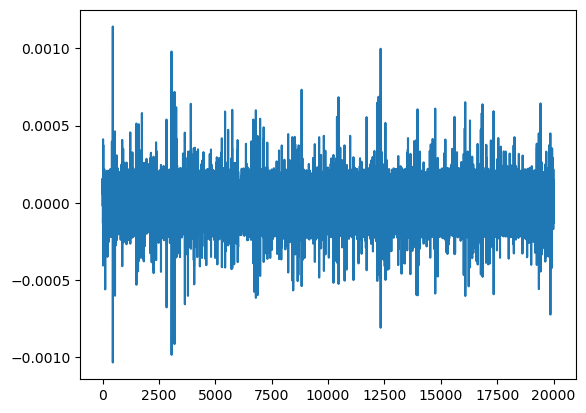

In [46]:
t_prices_df_0['gain'].plot()

<Axes: >

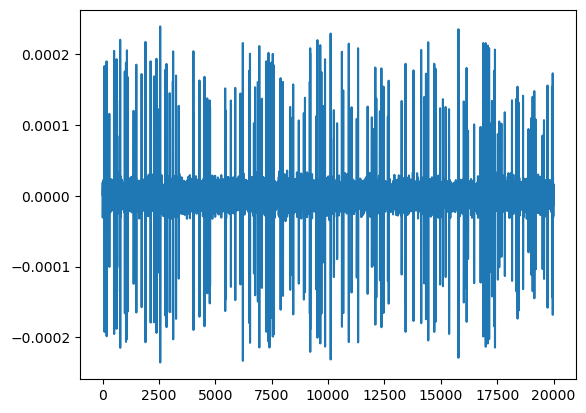

In [47]:
e_prices_df_0['gain'].plot()

In [49]:
t_prices_df_0['gain'].describe()

count    9.999000e+03
mean    -9.745101e-07
std      1.417561e-04
min     -1.032576e-03
25%     -6.238433e-05
50%      0.000000e+00
75%      5.987123e-05
max      1.141670e-03
Name: gain, dtype: float64

## Finding statistics

In [50]:
trades_df_0

,timestamp,buyer,seller,symbol,currency,price,quantity
0,3200,None,None,EMERALDS,XIRECS,9992.0,8
1,3400,None,None,TOMATOES,XIRECS,5009.0,2
2,5000,None,None,EMERALDS,XIRECS,9992.0,7
3,7000,None,None,TOMATOES,XIRECS,5010.0,4
4,9600,None,None,TOMATOES,XIRECS,4999.0,5
...,...,...,...,...,...,...,...
626,983800,None,None,EMERALDS,XIRECS,10008.0,3
627,985100,None,None,TOMATOES,XIRECS,4946.0,2
628,985600,None,None,EMERALDS,XIRECS,10008.0,6
629,993000,None,None,TOMATOES,XIRECS,4956.0,2
